# EMQA_L6_resid_price

**Romanian day-ahead price against residual load (load - wind - solar), hourly, 2023-01-01 to 2026-10-31: mean price in bins of 0.5 GW (bins with at least 20 hours) for 2023, the previous year and the current year to the cut-off; prints the OLS slope of price on residual load with month, hour and weekday fixed effects and HAC (Newey-West, 48 lags) standard errors, and the share of hours with residual load below 2 GW.**

Energy Markets Quantitative Analysis (EMQA), Lecture 6 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/EMQA/blob/main/Quantlets/L6/EMQA_L6_resid_price/EMQA_L6_resid_price.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/'

## Setup: chart style and data period

In [2]:
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings('ignore')

# course chart style: transparent background, no grid, legend at the bottom outside the axes, fixed colour per zone
PAL = {'RO': '#2a78d6', 'DE_LU': '#eb6834', 'HU': '#1baf7a', 'BG': '#eda100',
       'c5': '#e87ba4', 'c6': '#008300', 'c7': '#6250d6', 'c8': '#e34948'}
ZONE_LS = {'RO': '-', 'BG': '--', 'HU': '-.', 'DE_LU': ':'}
ZN = {'RO': 'Romania', 'BG': 'Bulgaria', 'HU': 'Hungary', 'DE_LU': 'Germany-Lux.'}
INK = '#222222'
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': INK, 'axes.labelcolor': INK, 'xtick.color': INK, 'ytick.color': INK,
    'text.color': INK, 'font.size': 11, 'axes.titlesize': 11.5, 'axes.labelsize': 11,
    'legend.fontsize': 10.5, 'legend.frameon': False, 'lines.linewidth': 1.4, 'font.family': 'DejaVu Sans'})


def legend_bottom(fig, ncol=4):
    """One legend for the whole figure, centred under the axes, outside the plotting area."""
    handles, labels = [], []
    for ax in fig.axes:
        for h, l in zip(*ax.get_legend_handles_labels()):
            if l not in labels:
                handles.append(h)
                labels.append(l)
    fig.legend(handles, labels, loc='lower center', ncol=ncol, bbox_to_anchor=(0.5, 0.0), frameon=False,
               handlelength=2.0, columnspacing=1.2)


def fl(x, k=4):
    """Rounding used for the numbers of the slides."""
    return None if x is None or np.isnan(float(x)) else round(float(x), k)


def show_numbers(d):
    for k, v in d.items():
        print(f'{k:<34} {v}')

Hourly means (15-min prices averaged to the hour); residual load R_t = load_t - wind_t - solar_t (GW). Regression: P_t = a + b R_t + month, hour and weekday fixed effects + e_t, HAC standard errors (48 lags).

In [3]:
TZ = 'Europe/Brussels'                     # delivery days in CET/CEST
END = pd.Timestamp('2026-10-31')               # cut-off of Lecture 6 = last complete month of the data
END_X = (END + pd.Timedelta(days=1)).tz_localize(TZ)
Y = END.year
YEARS = list(range(2019, Y + 1))
MON_EN = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
YTD = f'* {Y} = Jan-{MON_EN[END.month - 1]}'
LTM0 = pd.Timestamp('2025-11-01').tz_localize(TZ)    # first day of the last 12 months
MTU15 = pd.Timestamp('2025-10-01').tz_localize(TZ)   # 15-min market time unit from 1 Oct 2025

In [4]:
# day-ahead prices, EUR/MWh: hourly to 30 Sep 2025, 15-min from 1 Oct 2025 (SDAC); index in CET/CEST
PX = pd.read_csv(DATA + 'power_da_prices_native_utc.csv', parse_dates=['timestamp_utc']).set_index('timestamp_utc')
PX.index = PX.index.tz_convert(TZ)
PX['dur'] = PX['mtu_minutes'] / 60.0          # interval length in hours
PX = PX[PX.index < END_X]
LOC_YEAR = PX.index.year
print('prices:', PX.index.min(), 'to', PX.index.max(), '|', (PX['mtu_minutes'] == 15).sum(), '15-min intervals')

prices: 2015-01-01 01:00:00+01:00 to 2026-10-31 23:45:00+01:00 | 38020 15-min intervals


In [5]:
def hfloor(idx):
    """Start of the clock hour, computed in UTC (no ambiguity on the autumn DST day)."""
    return idx.tz_convert('UTC').floor('1h').tz_convert(TZ)


def load_gen(c):
    """Generation and load of country c (ro, bg, hu), MW, native resolution, CET/CEST index."""
    g = pd.read_csv(DATA + f'generation_{c}_mw_native_utc.csv', parse_dates=['timestamp_utc']).set_index('timestamp_utc')
    g.index = g.index.tz_convert(TZ)
    return g


def on_price_grid(g):
    """Generation columns on the price grid: hourly mean for hourly prices; 15-min value for 15-min prices
    (the hourly value is repeated when the source is hourly, as for Bulgaria)."""
    gg = g.drop(columns=['mtu_minutes']).copy()
    out = gg.resample('1h').mean().reindex(hfloor(PX.index)).set_axis(PX.index)
    q15 = PX['mtu_minutes'] == 15
    if (g['mtu_minutes'] == 15).loc[g.index >= MTU15].all():
        out.loc[q15] = gg.resample('15min').mean().reindex(PX.index[q15]).values
    return out


GN = {c.upper(): load_gen(c) for c in ('ro',)}
GR = {z: on_price_grid(GN[z]) for z in GN}
print({z: (str(g.index.min())[:10], str(g.index.max())[:10]) for z, g in GN.items()})

{'RO': ('2018-12-30', '2026-11-04')}


In [6]:
import statsmodels.api as sm

ro = GR['RO']
H = pd.DataFrame({'P': PX['RO'], 'dur': PX['dur'], 'load': ro['load'], 'wind': ro['wind_onshore'], 'solar': ro['solar']})
H = H[H.index >= pd.Timestamp('2023-01-01').tz_localize(TZ)]
HH = (H[['P', 'load', 'wind', 'solar']].mul(H['dur'], axis=0).groupby(hfloor(H.index)).sum()
      .div(H['dur'].groupby(hfloor(H.index)).sum(), axis=0)).dropna()           # hourly means
HH = HH[HH.index < END_X]
for c in ('load', 'wind', 'solar'):
    HH[c] = HH[c] / 1000.0                                                      # GW
HH['resid'] = HH['load'] - HH['wind'] - HH['solar']
fe = pd.get_dummies(pd.DataFrame({'m': HH.index.strftime('%Y-%m'), 'h': HH.index.hour.astype(str), 'w': HH.index.dayofweek.astype(str)}),
                    drop_first=True).astype(float)
fe.index = HH.index
R2 = sm.OLS(HH['P'], sm.add_constant(pd.concat([HH[['resid']], fe], axis=1))).fit(cov_type='HAC', cov_kwds={'maxlags': 48})

BINS = np.arange(-2.0, 9.01, 0.5)
RBIN, share2 = {}, {}
for y in (2023, Y - 1, Y):
    s_ = HH[HH.index.year == y]
    g_ = s_.groupby(pd.cut(s_['resid'], BINS), observed=True)['P'].agg(['mean', 'count'])
    g_ = g_[g_['count'] >= 20]
    RBIN[y] = (np.array([iv.mid for iv in g_.index]), g_['mean'].values)
    share2[y] = fl((s_['resid'] < 2).mean() * 100, 1)

print(len(HH), 'hours from', HH.index.min(), 'to', HH.index.max())
show_numbers({'reg.resid.b': fl(R2.params['resid'], 2), 'reg.resid.se': fl(R2.bse['resid'], 2),
              'reg.share_resid_below2_2023': share2[2023], f'reg.share_resid_below2_{Y}': share2[Y]})

33600 hours from 2023-01-01 00:00:00+01:00 to 2026-10-31 23:00:00+01:00
reg.resid.b                        28.32
reg.resid.se                       0.88
reg.share_resid_below2_2023        0.1
reg.share_resid_below2_2026        9.0


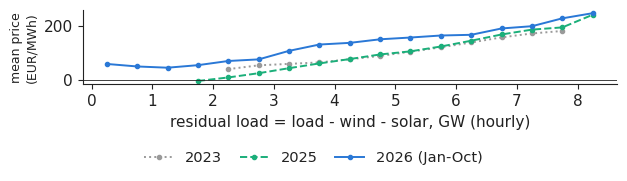

In [7]:
fig, ax = plt.subplots(figsize=(6.4, 1.85))
for y, col, ls in ((2023, '#9a9a9a', ':'), (Y - 1, PAL['HU'], '--'), (Y, PAL['RO'], '-')):
    x_, y_ = RBIN[y]
    ax.plot(x_, y_, color=col, ls=ls, marker='o', ms=3, lw=1.4, label=str(y) if y != Y else f'{Y} (Jan-{MON_EN[END.month - 1]})')
ax.axhline(0, color=INK, lw=0.6)
ax.set_xlabel('residual load = load - wind - solar, GW (hourly)')
ax.set_ylabel('mean price\n(EUR/MWh)', fontsize=9)
legend_bottom(fig, ncol=3)
fig.canvas.draw()
legend_h = max([lg.get_window_extent().height for lg in fig.legends] or [0.0]) / fig.bbox.height
fig.tight_layout(rect=(0, legend_h + 0.035, 1, 1))
plt.savefig('resid_price.png', dpi=150, bbox_inches='tight', transparent=True)
plt.show()